# Week 8 Lab (intro) - Read a password off the power with SPA

Before the statistics of CPA, the simplest side channel: **simple power analysis (SPA)** - reading what the
chip does straight off one power trace, by eye. The target is the `basic-passwdcheck` "Safe-o-matic 3000",
the same kind of character-by-character password check you glitched in week 6. Here nothing is glitched; the
check runs correctly, and we still pull the password out of it - one character at a time, by looking at how
long the chip works before it gives up.

Based on ChipWhisperer `sca101` Lab 2_1B.

**What you do, in order:**

1. Build and flash the password-check firmware.
2. Capture a right first character and a wrong one; the difference from a reference stays flat, then erupts
   where the check takes a different code path.
3. Difference every one of the 36 first-character guesses against a reference: one erupts, the rest stay flat.
4. Turn "odd one out" into a number with the **sum of absolute differences (SAD)** against a reference.
5. Loop that over all five positions and recover the whole password, `h0px3`, with no brute force.

**Hardware:** Husky + CW313 + CW312T-SAM4S, MEASURE SMA connected (the power trace comes over that coax). No
crowbar. The notebook finds your ChipWhisperer install automatically, so it runs from anywhere.

In [1]:
SCOPETYPE = 'OPENADC'
PLATFORM  = 'CW312_SAM4S'
SS_VER    = 'SS_VER_2_1'

In [2]:
# Locate the ChipWhisperer install from the installed package, so this notebook
# runs from anywhere - it does not need to sit inside the chipwhisperer tree.
import os, chipwhisperer as cw
CWROOT = os.path.normpath(os.path.join(os.path.dirname(cw.__file__), "..", ".."))
SETUP  = os.path.join(CWROOT, "jupyter", "Setup_Scripts", "Setup_Generic.ipynb")
FW_SRC = os.path.join(CWROOT, "firmware", "mcu", "basic-passwdcheck")
# drive-less, forward-slash root for the %%bash build cell; the cell itself finds
# the right mount prefix (/mnt/c on WSL, /c on Git-Bash, / on macOS/Linux).
CW_BASH = (CWROOT[0].lower() + CWROOT[2:].replace("\\", "/")) if os.name == "nt" else CWROOT.lstrip("/")
print("ChipWhisperer:", CWROOT)

ChipWhisperer: C:\Users\MykhailoOkhrimenko\ChipWhisperer\chipwhisperer


In [3]:
%run "$SETUP"    # brings up scope, prog, target

INFO: Found ChipWhisperer😍


scope.gain.gain                          changed from 0                         to 22                       
scope.gain.db                            changed from 15.0                      to 25.091743119266056       
scope.adc.samples                        changed from 131124                    to 5000                     
scope.clock.clkgen_freq                  changed from 0                         to 7363636.363636363        
scope.clock.adc_freq                     changed from 0                         to 29454545.454545453       
scope.clock.adc_rate                     changed from 0.0                       to 29454545.454545453       
scope.io.tio1                            changed from serial_tx                 to serial_rx                
scope.io.tio2                            changed from serial_rx                 to serial_tx                
scope.io.hs2                             changed from None                      to clkgen                   
scope.glitch.phase_

In [4]:
%%bash -s "$PLATFORM" "$SS_VER" "$CW_BASH"
# find the firmware dir under whichever mount this bash uses (WSL /mnt/c, Git-Bash /c, macOS /)
FW=""
for p in "/mnt/$3" "/$3"; do
  [ -d "$p/firmware/mcu/basic-passwdcheck" ] && FW="$p/firmware/mcu/basic-passwdcheck" && break
done
[ -z "$FW" ] && { echo "firmware dir not found for root: $3" >&2; exit 1; }
cd "$FW"
make PLATFORM=$1 CRYPTO_TARGET=NONE SS_VER=$2

SS_VER set to SS_VER_2_1


SS_VER set to SS_VER_2_1


.


Welcome to another exciting ChipWhisperer target build!!


arm-none-eabi-gcc (15:13.2.rel1-2) 13.2.1 20231009
Copyright (C) 2023 Free Software Foundation, Inc.


This is free software; see the source for copying conditions.  There is NO
warranty; not even for M

... (75 outputs left out)

+ Built for platform Microchip SAM4S with:


+ CRYPTO_TARGET = NONE


+ CRYPTO_OPTIONS = AES128C


+--------------------------------------------------------


In [5]:
fw_path = os.path.join(FW_SRC, "basic-passwdcheck-{}.hex".format(PLATFORM))
cw.program_target(scope, prog, fw_path)

## The code we are reading

The target boots, prints a banner, and waits for a password. The part we capture is this loop (it is
bracketed by `trigger_high()` / `trigger_low()`, so the trace starts at the first compare):

```c
char correct_passwd[] = "h0px3";
...
for(uint8_t i = 0; i < sizeof(correct_passwd); i++){
    if (correct_passwd[i] != passwd[i]){
        passbad = 1;
        break;                 // bail at the first wrong character
    }
}
```

The loop checks one character per iteration and **breaks at the first mismatch**. So if the first character
is wrong, it does one iteration and stops. If the first is right and the second wrong, it does two. Every
correct leading character buys one more iteration before the break - and one more iteration is a visible bit
more work on the power trace. That is the whole leak: *how far the loop got* tells us *how many leading
characters were right*.

We never need the device to say "access granted". We only watch how long it thinks.

In [6]:
import time
scope.adc.samples = 3000

def cap_pass_trace(pass_guess):
    """Reset the target, flush its boot banner, send one password guess, return the power trace."""
    scope.io.nrst = "low";  time.sleep(0.05)     # SAM4S wants a real reset pulse
    scope.io.nrst = "high_z"; time.sleep(0.15)   # let it boot and print the banner
    n = target.in_waiting()
    while n > 0:                                 # drain the banner so the trace is just the compare
        target.read(n, 10); time.sleep(0.01); n = target.in_waiting()
    scope.arm()
    target.write(pass_guess)
    if scope.capture():
        print("Timeout during acquisition")
    return scope.get_last_trace()

import numpy as np

def avg_trace(pass_guess, n=4):
    """Average n captures of the same guess - the per-character leak is small, averaging beats jitter/noise."""
    return np.mean([cap_pass_trace(pass_guess) for _ in range(n)], axis=0)

t = cap_pass_trace("h\n")
print("trace length:", len(t), "| min/max: %.3f / %.3f" % (t.min(), t.max()))

trace length: 3000 | min/max: -0.319 / 0.180


## Right first character vs wrong: where the trace splits

Send `h` (the real first character) and `0` (wrong). Both are processed the same way at first, so the raw
traces (left) look alike. To see *where* they part, subtract a common reference capture (a wrong character)
and plot the absolute difference (right): `|h - ref|` sits flat while the two paths agree, then **erupts**
at the sample where the correct character sent the loop round one more time. `|0 - ref|` - wrong, like the
reference - stays flat throughout. That onset is the leak.

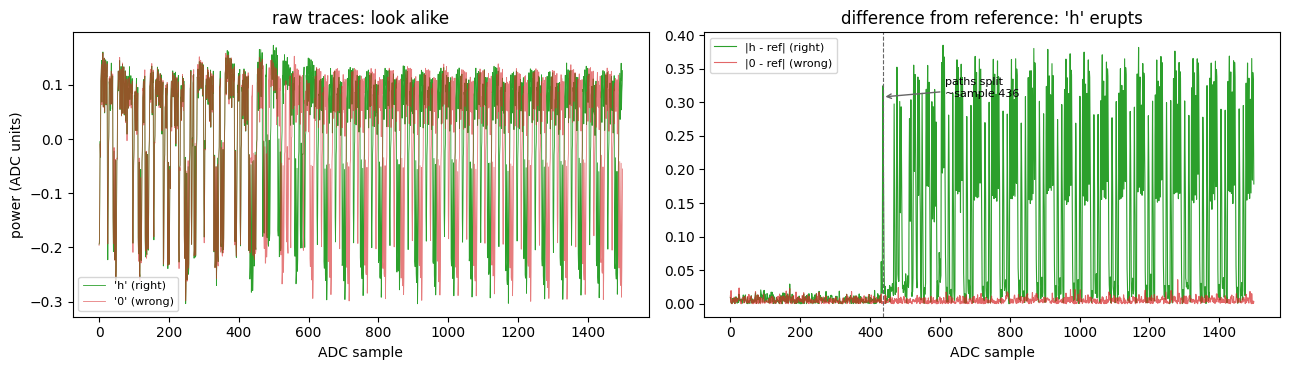

In [7]:
%matplotlib inline
import matplotlib.pyplot as plt

W = 1500                                          # the split and its aftermath live in the first ~half
ref     = avg_trace("\x01\n")                     # 0x01 is never in the password -> a wrong reference
t_right = avg_trace("h\n")
t_wrong = avg_trace("0\n")
d_right = np.abs(t_right - ref)
onset   = int(np.argmax(d_right[:W] > 0.25 * d_right[:W].max()))  # first sample that clears the noise band

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
ax1.plot(t_right[:W], color="tab:green", lw=0.6, label="'h' (right)")
ax1.plot(t_wrong[:W], color="tab:red",   lw=0.6, alpha=0.6, label="'0' (wrong)")
ax1.legend(fontsize=8); ax1.set_xlabel("ADC sample"); ax1.set_ylabel("power (ADC units)")
ax1.set_title("raw traces: look alike")
ax2.plot(d_right[:W],               color="tab:green", lw=0.8, label="|h - ref| (right)")
ax2.plot(np.abs(t_wrong - ref)[:W], color="tab:red",   lw=0.8, alpha=0.7, label="|0 - ref| (wrong)")
ax2.axvline(onset, color="0.4", ls="--", lw=0.8)
ax2.annotate("paths split\n~sample %d" % onset, (onset, d_right[:W].max() * 0.8),
             xytext=(onset + 180, d_right[:W].max() * 0.8),
             arrowprops=dict(arrowstyle="->", color="0.4"), fontsize=8)
ax2.legend(fontsize=8); ax2.set_xlabel("ADC sample"); ax2.set_title("difference from reference: 'h' erupts")
plt.tight_layout(); plt.show()

## All 36 first characters: spot the outlier

Now send every valid character as the first guess and plot each one's **difference from the reference**,
`|guess - ref|`. The 35 wrong characters take the same short path as the reference, so they stay in a flat
noise band near zero. The one correct character (`h`) runs the loop a step further and **erupts** out of the
band - the outlier you can point at.

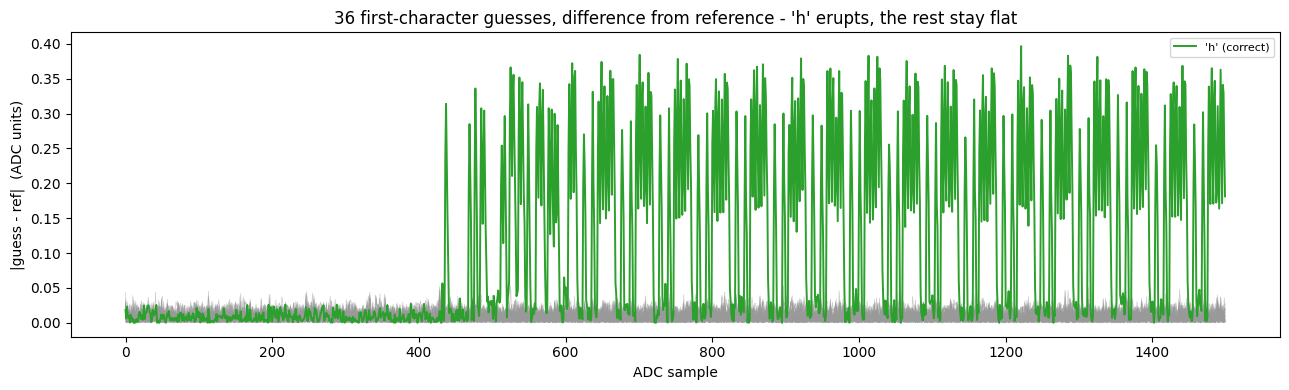

In [8]:
CHARS = 'abcdefghijklmnopqrstuvwxyz0123456789'
plt.figure(figsize=(13, 4))
for c in CHARS:
    d = np.abs(avg_trace(c + "\n", 2) - ref)
    plt.plot(d[:W], color=("tab:green" if c == "h" else "0.6"),
             lw=(1.4 if c == "h" else 0.5), alpha=(1.0 if c == "h" else 0.5),
             zorder=(3 if c == "h" else 1), label=("'h' (correct)" if c == "h" else None))
plt.xlabel("ADC sample"); plt.ylabel("|guess - ref|  (ADC units)")
plt.title("36 first-character guesses, difference from reference - 'h' erupts, the rest stay flat")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## From "looks different" to a number: SAD

Reading the outlier by eye works, but to automate it we need a score. Pick one guess as a **reference**
(any wrong character will do) and, for each other guess, take the **sum of absolute differences (SAD)** of
its trace from the reference: `sum(abs(trace - reference))`. Wrong guesses match the reference and score
near 0; the one correct character diverges and scores high. The character with the largest SAD is the
right one.

highest SAD: h=410  4=65  z=64  s=64  8=64
recovered first character: 'h'


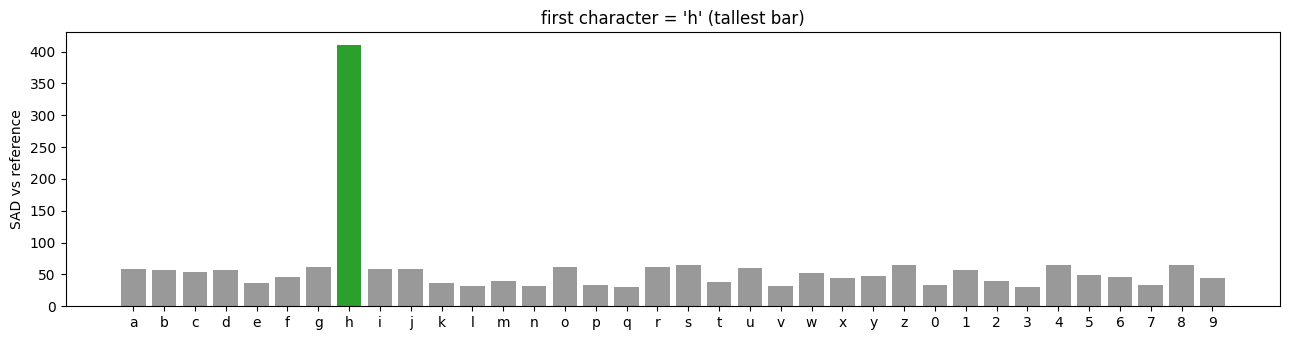

In [9]:
def recover_char(prefix):
    """SAD of each candidate's trace against a fixed reference; return (scores dict, best char)."""
    ref = cap_pass_trace(prefix + "\x01\n")        # 0x01 is never part of the password -> a wrong reference
    scores = {}
    for c in CHARS:
        tr = cap_pass_trace(prefix + c + "\n")
        scores[c] = float(np.sum(np.abs(tr - ref)))
    best = max(scores, key=scores.get)
    return scores, best

scores, best = recover_char("")
order = sorted(scores, key=scores.get, reverse=True)
print("highest SAD:", "  ".join(f"{c}={scores[c]:.0f}" for c in order[:5]))
print("recovered first character:", repr(best))

plt.figure(figsize=(13, 3.5))
cols = ["tab:green" if c == best else "0.6" for c in CHARS]
plt.bar(range(len(CHARS)), [scores[c] for c in CHARS], color=cols)
plt.xticks(range(len(CHARS)), list(CHARS)); plt.ylabel("SAD vs reference")
plt.title(f"first character = '{best}' (tallest bar)"); plt.tight_layout(); plt.show()

## Full attack: one character at a time

The leak compounds. Once the first character is known, feed it as a fixed prefix and attack the second: now
the correct second character is the one that makes the loop run to iteration 3. Repeat, growing the known
prefix, and the whole password falls out in `5 x 36` captures instead of `36^5` guesses.

In [10]:
guessed = ""
for position in range(5):
    _, c = recover_char(guessed)
    guessed += c
    print(f"position {position}: recovered '{c}'  ->  password so far: {guessed!r}")
print("\nRecovered password:", repr(guessed))
print("Correct password  :", repr("h0px3"))
print("MATCH" if guessed == "h0px3" else "MISMATCH - re-check gain / sample window")

position 0: recovered 'h'  ->  password so far: 'h'


position 1: recovered '0'  ->  password so far: 'h0'


position 2: recovered 'p'  ->  password so far: 'h0p'


position 3: recovered 'x'  ->  password so far: 'h0px'


position 4: recovered '3'  ->  password so far: 'h0px3'

Recovered password: 'h0px3'
Correct password  : 'h0px3'
MATCH


## What this shows, and its limit

The password never left the chip and nothing was faulted - the leak is purely *timing*, read off power.
That is SPA: the secret changed the **sequence of operations**, and the sequence is visible by eye.

SPA stops working the moment the secret stops changing what the chip *does* and only changes a value it
*handles* - one key byte inside AES moves a few ADC counts at one instant, far below the noise, and no amount
of looking finds it. That is where this week's main lab, CPA, takes over (`02 - CPA on AES.ipynb`).

## Submission

A screenshot of the recovered password (`h0px3`) printed by the full-attack cell, and one of the figures
that shows *why* it works - either the 36-trace overlay with the outlier, or the SAD bar chart.

In [11]:
scope.dis()
target.dis()